# Optimización de hiperparámetros en Kaggle: VGG19 con fine-tuning y data augmentation

Misma búsqueda que el notebook de ResNet50 en Colab, pero con **VGG19** y preparado para **Kaggle**.

| Se optimiza | Rango |
|---|---|
| Learning rate del fine-tuning | 1e-6 a 1e-4 (logarítmico) |
| Bloques descongelados | `block5` o `block5 + block4` |
| Épocas de calentamiento (solo la cabeza, antes del fine-tuning) | 0, 5 o 10 |
| Intensidad de la data augmentation | 0,1 a 0,3 (0,2 = la del notebook principal) |
| Dropout de la cabeza | 0,3 a 0,7 |

**Fijos:** 20 épocas de fine-tuning (el calentamiento se suma aparte), batch 32, entrada 256×256, cabeza
`GlobalAveragePooling2D` + `Dense(128)` + dropout + sigmoide, Adam con *cosine decay*, `class_weight`, learning rate
del calentamiento 1e-4 y semilla fija durante la búsqueda.

| Calentamiento | Bloques | Fases | Total |
|---|---|---|---|
| 0 | `block5` | 20 con `block5` | 20 |
| 0 | `block5 + block4` | 20 con `block5` y `block4` | 20 |
| 5 o 10 | `block5` | calentamiento + 20 con `block5` | 25 o 30 |
| 5 o 10 | `block5 + block4` | calentamiento + 10 con `block5` + 10 con `block5` y `block4` (lr / 2) | 25 o 30 |

**Métrica objetivo:** AUC promedio de los folds 1 y 2. El fold 3 no se entrena durante la búsqueda. Si el AUC del
fold 1 queda en el 25 % peor de las pruebas anteriores, la prueba se corta ahí (*pruning*).

## Antes de correrlo en Kaggle

1. **Settings → Accelerator:** `GPU T4 x2` o `GPU P100`. TensorFlow usa una sola GPU, así que cualquiera de las dos sirve.
2. **Settings → Internet: on.** Hace falta para clonar el repo y descargar los pesos de ImageNet (Kaggle pide
   verificar el teléfono la primera vez).
3. **Para dejarlo corriendo sin tener la pestaña abierta:** *Save Version → Save & Run All (Commit)*. Corre en segundo
   plano (hasta 12 horas) y todo lo que queda en `/kaggle/working` se guarda como salida de esa versión.
4. **Para retomar una corrida anterior:** *Add Input → Notebook Output Files* y elegí la salida de la versión anterior
   de este notebook. Al empezar, el notebook copia el estudio y los entrenamientos guardados y sigue desde ahí.

## Preparación

In [1]:
import os
import shutil
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/ana-castillo-zuain/procesamiento-de-imagenes.git"
DIR_REPO = "/tmp/repo"   # fuera de /kaggle/working, para que el repo (490 MB) no se guarde como salida

try:
    import optuna
except ImportError:
    subprocess.run(["pip", "install", "-q", "optuna"], check=True)

if not os.path.isdir(DIR_REPO):
    r = subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, DIR_REPO], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("No pude clonar el repo. Revisá que en Settings esté activado Internet.\n" + r.stderr[-500:])
os.chdir(DIR_REPO)
print("Trabajando en", os.getcwd())

Trabajando en /tmp/repo


In [2]:
import gc
import json
import pickle
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# La GPU pide memoria a medida que la necesita (evita errores de memoria al encadenar muchos entrenamientos).
# Tiene que ejecutarse antes de cualquier otra operación de TensorFlow.
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import optuna
from tensorflow import keras
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input, Lambda
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score

print("GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("ATENCIÓN: no hay GPU. Elegí GPU T4 x2 o P100 en Settings -> Accelerator, si no va a tardar muchísimo.")
print("Optuna", optuna.__version__)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Optuna 5.0.0


## Datos

Mismas celdas que en el notebook principal: arman y validan los 3 folds y cargan las imágenes en memoria.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

# --- Rutas (relativas a la raíz del repo: la celda de preparación ya se para ahí)
RAIZ = Path(".")
DIR_IMG = RAIZ / "data" / "raw" / "images"
DIR_LAB = RAIZ / "data" / "raw" / "labels"
DIR_SPLITS = RAIZ / "data" / "splits"

FOLDS = ["solarpanels_val", "geo_kingston_val", "PV01_val"]

if not DIR_IMG.is_dir() or not DIR_LAB.is_dir() or not DIR_SPLITS.is_dir():
    raise FileNotFoundError("No encontré data/raw y data/splits en %s. Pasate a la raíz del repo "
                            "(por ejemplo, corré la celda de preparación) y volvé a correr." % Path.cwd())


def grupo_de(nombre: str) -> str:
    """Los nombres de archivo delatan de qué fuente viene cada imagen."""
    if nombre.startswith("PV01"):           return "PV01"
    if nombre.startswith("solarpanels_hd"): return "solarpanels_hd"
    if nombre.startswith("kingston2"):      return "kingston2"
    if nombre.startswith("kingston_"):      return "kingston"
    return "geo_unknown"


def leer_yolo(ruta):
    """Lee un .txt en formato YOLO -> lista de (clase, cx, cy, w, h) normalizados."""
    cajas = []
    for linea in Path(ruta).read_text().splitlines():
        if not linea.strip():
            continue
        partes = linea.split()
        cajas.append((int(float(partes[0])), *map(float, partes[1:5])))
    return cajas


# Clases 1 y 2 no son paneles. Si un .txt sólo tiene esas filas, la imagen es negativa.
CLASES_NEGATIVAS = {1, 2}


def es_panel(cls):
    return cls not in CLASES_NEGATIVAS


# Todas las imágenes y su label calculado desde los labels crudos (para la validación 6)
TODAS = sorted(p.stem for p in DIR_IMG.glob("*.png"))
LABEL_RAW = {n: int(any(es_panel(c[0]) for c in leer_yolo(DIR_LAB / (n + ".txt")))) for n in TODAS}
print("data/raw: %d imágenes | %d positivas | %d negativas"
      % (len(TODAS), sum(LABEL_RAW.values()), len(TODAS) - sum(LABEL_RAW.values())))


def leer_lista(ruta):
    """Líneas no vacías de un train.txt / val.txt (rutas relativas a la raíz del repo)."""
    return [l.strip() for l in Path(ruta).read_text().splitlines() if l.strip()]


def tiene_cajas(ruta):
    """1 si el .txt limpio tiene al menos una línea no vacía, 0 si está vacío."""
    return int(any(l.strip() for l in Path(ruta).read_text().splitlines()))


def armar_fold(fold):
    """Una fila por imagen del fold: ruta, nombre, fuente, split y ruta de su etiqueta limpia."""
    dir_fold = DIR_SPLITS / fold
    filas = []
    for sp in ("train", "val"):
        for ruta in leer_lista(dir_fold / (sp + ".txt")):
            nombre = Path(ruta).stem
            filas.append(dict(ruta_imagen=ruta, nombre=nombre, fuente=grupo_de(nombre), split=sp,
                              ruta_label=(dir_fold / "labels" / sp / (nombre + ".txt")).as_posix()))
    return pd.DataFrame(filas, columns=["ruta_imagen", "nombre", "fuente", "split", "ruta_label"])


def validar_estructura(fold, df):
    """Validaciones 1 a 5: repetidas, fuentes cruzadas, archivos faltantes, huérfanos y cobertura."""
    errores = []
    tr, va = df[df.split == "train"], df[df.split == "val"]

    for sp, sub in (("train", tr), ("val", va)):
        if sub.empty:
            errores.append("%s está vacío" % sp)
        rep = sorted(set(sub.nombre[sub.nombre.duplicated()]))
        if rep:
            errores.append("%s tiene %d imágenes repetidas: %s" % (sp, len(rep), rep[:5]))
    cruzadas = sorted(set(tr.nombre) & set(va.nombre))
    if cruzadas:
        errores.append("%d imágenes en train y val a la vez: %s" % (len(cruzadas), cruzadas[:5]))

    fuentes = sorted(set(tr.fuente) & set(va.fuente))
    if fuentes:
        errores.append("fuentes en train y val a la vez: %s" % fuentes)

    sin_imagen = [r for r in df.ruta_imagen if not Path(r).is_file()]
    if sin_imagen:
        errores.append("%d imágenes listadas no existen: %s" % (len(sin_imagen), sin_imagen[:5]))
    sin_label = [r for r in df.ruta_label if not Path(r).is_file()]
    if sin_label:
        errores.append("%d imágenes sin etiqueta: %s" % (len(sin_label), sin_label[:5]))

    for sp, sub in (("train", tr), ("val", va)):
        en_disco = {p.stem for p in (DIR_SPLITS / fold / "labels" / sp).glob("*.txt")}
        huerfanas = sorted(en_disco - set(sub.nombre))
        if huerfanas:
            errores.append("labels/%s tiene %d etiquetas huérfanas: %s" % (sp, len(huerfanas), huerfanas[:5]))

    afuera = sorted(set(TODAS) - set(df.nombre))
    if afuera:
        errores.append("%d imágenes de data/raw no están en ningún split: %s" % (len(afuera), afuera[:5]))
    ajenas = sorted(set(df.nombre) - set(TODAS))
    if ajenas:
        errores.append("%d imágenes listadas no están en data/raw/images: %s" % (len(ajenas), ajenas[:5]))

    if errores:
        raise ValueError("[%s] validación fallida:\n  - %s" % (fold, "\n  - ".join(errores)))


def validar_contra_raw(fold, df):
    """Validación 6: el label de data/splits tiene que coincidir con el calculado desde data/raw/labels."""
    raw = df.nombre.map(LABEL_RAW)
    dif = df[df.label != raw]
    if len(dif):
        tabla = pd.DataFrame(dict(fold=fold, nombre=dif.nombre, split=dif.split,
                                  label_splits=dif.label, label_raw=raw[dif.index]))
        print(tabla.to_string(index=False))
        raise ValueError("[%s] %d imágenes con label distinto entre data/splits y data/raw/labels"
                         % (fold, len(dif)))


# Primero se arman y validan los tres folds. Recién después (sección 5) se escribe algo en disco.
DFS = {}
for fold in FOLDS:
    df = armar_fold(fold)
    validar_estructura(fold, df)
    df["label"] = [tiene_cajas(r) for r in df.ruta_label]
    validar_contra_raw(fold, df)
    DFS[fold] = df
    print("%-17s OK  (train %d, val %d)"
          % (fold, (df.split == "train").sum(), (df.split == "val").sum()))

data/raw: 900 imágenes | 805 positivas | 95 negativas
solarpanels_val   OK  (train 584, val 316)
geo_kingston_val  OK  (train 794, val 106)
PV01_val          OK  (train 422, val 478)


In [4]:
from concurrent.futures import ThreadPoolExecutor


def cargar_rgb(ruta):
    """Imagen como RGB uint8 (algunas PNG están en modo paleta)."""
    with Image.open(ruta) as im:
        return np.array(im.convert("RGB"))


# Cada imagen se lee una sola vez (en paralelo) y después cada fold toma las suyas
rutas = sorted({r for df in DFS.values() for r in df.ruta_imagen})
with ThreadPoolExecutor() as ex:
    IMG = dict(zip(rutas, ex.map(cargar_rgb, rutas)))
print("%d imágenes en memoria" % len(IMG))


def xy(fold, split):
    sub = DFS[fold][DFS[fold].split == split]
    X = np.stack([IMG[r] for r in sub.ruta_imagen])        # uint8 0-255, (N, 256, 256, 3)
    y = sub.label.to_numpy().astype("float32")              # 1 = con paneles, 0 = sin paneles
    return X, y


X_train_1, y_train_1 = xy("solarpanels_val", "train")
X_val_1,   y_val_1   = xy("solarpanels_val", "val")
X_train_2, y_train_2 = xy("geo_kingston_val", "train")
X_val_2,   y_val_2   = xy("geo_kingston_val", "val")
X_train_3, y_train_3 = xy("PV01_val", "train")
X_val_3,   y_val_3   = xy("PV01_val", "val")

for i, (Xt, yt, Xv, yv) in enumerate([(X_train_1, y_train_1, X_val_1, y_val_1),
                                      (X_train_2, y_train_2, X_val_2, y_val_2),
                                      (X_train_3, y_train_3, X_val_3, y_val_3)], start=1):
    print(f"Fold {i}: train {Xt.shape} pos {int(yt.sum())} neg {int(len(yt) - yt.sum())} | "
          f"val {Xv.shape} pos {int(yv.sum())} neg {int(len(yv) - yv.sum())}")

900 imágenes en memoria
Fold 1: train (584, 256, 256, 3) pos 521 neg 63 | val (316, 256, 256, 3) pos 284 neg 32
Fold 2: train (794, 256, 256, 3) pos 761 neg 33 | val (106, 256, 256, 3) pos 44 neg 62
Fold 3: train (422, 256, 256, 3) pos 328 neg 94 | val (478, 256, 256, 3) pos 477 neg 1


In [5]:
# --- Dónde se guarda todo: /kaggle/working se conserva como salida de la versión (Save Version)
DIR_TRABAJO = Path("/kaggle/working/optuna_vgg19")
DIR_TRABAJO.mkdir(parents=True, exist_ok=True)

# Si se agregó como input la salida de una versión anterior, se copia para retomar donde quedó
anteriores = sorted(Path("/kaggle/input").glob("**/optuna_vgg19/optuna_vgg19.db"))
if anteriores and not (DIR_TRABAJO / "optuna_vgg19.db").is_file():
    shutil.copytree(anteriores[0].parent, DIR_TRABAJO, dirs_exist_ok=True)
    print("Retomando la corrida guardada en", anteriores[0].parent)

# --- Hiperparámetros fijos
SEED_VALUE = 41
IMG_SIZE = 256
BATCH_SIZE = 32
DENSE_UNITS = 128
EPOCAS_FT = 20            # épocas con el extractor descongelado (el calentamiento se suma aparte)
LR_CALENTAMIENTO = 1e-4   # learning rate de las épocas de calentamiento (solo la cabeza)

# --- Búsqueda
N_PRUEBAS = 20            # pruebas en total (las ya hechas en versiones anteriores cuentan)
FOLDS_BUSQUEDA = (1, 2)   # la métrica objetivo es el AUC promedio de estos folds

# --- Evaluación final
SEMILLAS = [41, 42, 43]   # semillas para reentrenar la mejor configuración y la base en los 3 folds

# Configuración del notebook principal (VGG19, fine-tuning de block5 + data augmentation)
CONFIG_BASE = dict(lr=1e-5, bloques=1, calentamiento=0, intensidad=0.2, dropout=0.6)

FOLDS_CV = {
    1: ("solarpanels_val",  X_train_1, y_train_1, X_val_1, y_val_1),
    2: ("geo_kingston_val", X_train_2, y_train_2, X_val_2, y_val_2),
    3: ("PV01_val",         X_train_3, y_train_3, X_val_3, y_val_3),
}

## Modelo y entrenamiento de un fold

In [6]:
def capas_aumentacion(intensidad):
    """Data augmentation con un solo factor de intensidad (0,2 = la configuración del notebook anterior)."""
    return Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),                     # siempre activo
        tf.keras.layers.RandomRotation(1.25 * intensidad, fill_mode="reflect"),    # 0,2 -> 0,25 (hasta ±90°)
        tf.keras.layers.RandomZoom(intensidad, fill_mode="reflect"),
        tf.keras.layers.RandomBrightness(intensidad, value_range=(0, 255)),
        tf.keras.layers.RandomContrast(intensidad),
    ], name="aumentacion")


def construir_vgg19(cfg):
    """VGG19 pre-entrenada (congelada al principio) + data augmentation + cabeza propia."""
    forma = (IMG_SIZE, IMG_SIZE, 3)
    base = tf.keras.applications.VGG19(input_shape=forma, include_top=False, weights="imagenet")
    entrada = Input(shape=forma)
    x = capas_aumentacion(cfg["intensidad"])(entrada)                       # antes del preprocesamiento (0-255)
    x = Lambda(tf.keras.applications.vgg19.preprocess_input, name="preprocesamiento")(x)
    x = base(x, training=False)                                              # extractor siempre en modo inferencia
    x = GlobalAveragePooling2D()(x)
    x = Dense(DENSE_UNITS, activation="relu")(x)
    x = Dropout(cfg["dropout"])(x)
    salida = Dense(1, activation="sigmoid")(x)
    return Model(entrada, salida, name="VGG19"), base


def configurar_entrenables(base, desde):
    """desde=None: todo congelado. desde="block5": descongela desde la primera capa de block5 hasta el final.
    (VGG19 no tiene BatchNorm; la condición queda por si se cambia de red.)"""
    capas = base.layers
    if desde is None:
        inicio = len(capas)
    else:
        inicio = next(i for i, capa in enumerate(capas) if capa.name.startswith(desde))
    base.trainable = True
    for i, capa in enumerate(capas):
        capa.trainable = i >= inicio and not isinstance(capa, tf.keras.layers.BatchNormalization)


def fases_de(cfg):
    """Fases de entrenamiento según el calentamiento y los bloques (ver la tabla del principio)."""
    fases = []
    if cfg["calentamiento"] > 0:
        fases.append(dict(desde=None, epocas=cfg["calentamiento"], lr=LR_CALENTAMIENTO, nombre="solo cabeza"))
    if cfg["bloques"] == 1:
        fases.append(dict(desde="block5", epocas=EPOCAS_FT, lr=cfg["lr"], nombre="cabeza + block5"))
    elif cfg["calentamiento"] == 0:
        fases.append(dict(desde="block4", epocas=EPOCAS_FT, lr=cfg["lr"], nombre="cabeza + block5 + block4"))
    else:
        mitad = EPOCAS_FT // 2
        fases.append(dict(desde="block5", epocas=mitad, lr=cfg["lr"], nombre="cabeza + block5"))
        fases.append(dict(desde="block4", epocas=EPOCAS_FT - mitad, lr=cfg["lr"] / 2,
                          nombre="cabeza + block5 + block4"))
    return fases


def compilar(model, lr, epocas, n_train):
    pasos = int(np.ceil(n_train / BATCH_SIZE)) * epocas
    schedule = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=lr, decay_steps=pasos)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=schedule),
                  loss=tf.keras.losses.BinaryCrossentropy(),
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])


def entrenar_fold(cfg, i, semilla=SEED_VALUE, verbose=0):
    """Entrena un fold con la configuración cfg. Devuelve (y_val, prob_val, historial)."""
    fold, X_tr, y_tr, X_va, y_va = FOLDS_CV[i]
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)

    n, n_pos = len(y_tr), int(y_tr.sum())
    pesos = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}   # compensa el desbalance

    model, base = construir_vgg19(cfg)
    hist, epoca, cortes = {}, 0, []
    for fase in fases_de(cfg):
        configurar_entrenables(base, fase["desde"])
        compilar(model, fase["lr"], fase["epocas"], n)        # recompilar para que tome el cambio de trainable
        cortes.append(epoca)
        h = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                      initial_epoch=epoca, epochs=epoca + fase["epocas"],
                      batch_size=BATCH_SIZE, class_weight=pesos, shuffle=True, verbose=verbose)
        for clave, valores in h.history.items():
            hist.setdefault(clave, []).extend(valores)
        epoca += fase["epocas"]
    hist["_cortes"] = cortes

    prob = model.predict(X_va, batch_size=BATCH_SIZE, verbose=0).ravel()
    del model, base
    gc.collect()
    return y_va.astype(int), prob, hist


for cfg in (CONFIG_BASE, dict(CONFIG_BASE, calentamiento=10, bloques=2)):
    print(cfg, "->", [(f["nombre"], f["epocas"], f["lr"]) for f in fases_de(cfg)])

{'lr': 1e-05, 'bloques': 1, 'calentamiento': 0, 'intensidad': 0.2, 'dropout': 0.6} -> [('cabeza + block5', 20, 1e-05)]
{'lr': 1e-05, 'bloques': 2, 'calentamiento': 10, 'intensidad': 0.2, 'dropout': 0.6} -> [('solo cabeza', 10, 0.0001), ('cabeza + block5', 10, 1e-05), ('cabeza + block5 + block4', 10, 5e-06)]


## Búsqueda

La primera prueba es la configuración base del notebook anterior, como referencia. Las 8 primeras se eligen al azar y
después Optuna (TPE) se concentra en las zonas que mejor van dando.

El estudio se guarda en `DIR_TRABAJO` (dentro de `/kaggle/working`). Para retomar en otra versión, agregá como input
la salida de la versión anterior: las pruebas terminadas se cargan y la que quedó a medias se repite una vez.

In [7]:
DB = DIR_TRABAJO / "optuna_vgg19.db"   # /kaggle/working es disco local: SQLite se guarda directo ahí


def objetivo(trial):
    cfg = dict(
        lr=trial.suggest_float("lr", 1e-6, 1e-4, log=True),
        bloques=trial.suggest_categorical("bloques", [1, 2]),
        calentamiento=trial.suggest_categorical("calentamiento", [0, 5, 10]),
        intensidad=trial.suggest_float("intensidad", 0.1, 0.3),
        dropout=trial.suggest_float("dropout", 0.3, 0.7),
    )
    print(f"\n--- Prueba {trial.number}: {cfg}")
    aucs = []
    for paso, i in enumerate(FOLDS_BUSQUEDA):
        y, p, _ = entrenar_fold(cfg, i)
        aucs.append(roc_auc_score(y, p))
        trial.set_user_attr(f"auc_fold{i}", float(aucs[-1]))
        print(f"    fold {i}: AUC {aucs[-1]:.3f}")
        trial.report(float(np.mean(aucs)), step=paso)
        if paso == 0 and trial.should_prune():               # solo se corta después del fold 1
            print("    cortada (pruning)")
            raise optuna.TrialPruned()
    print(f"    AUC promedio folds {FOLDS_BUSQUEDA}: {np.mean(aucs):.3f}")
    return float(np.mean(aucs))


storage = optuna.storages.RDBStorage(
    url=f"sqlite:///{DB}",
    heartbeat_interval=60, grace_period=180,                          # detecta pruebas que quedaron a medias
    failed_trial_callback=optuna.storages.RetryFailedTrialCallback(max_retry=1),
)
study = optuna.create_study(
    study_name="vgg19_ft_aug", storage=storage, direction="maximize", load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEED_VALUE, n_startup_trials=8),
    pruner=optuna.pruners.PercentilePruner(25.0, n_startup_trials=6, n_warmup_steps=0),
)
if len(study.trials) == 0:
    study.enqueue_trial(CONFIG_BASE)                                  # la primera prueba es la configuración base

hechas = sum(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED) for t in study.trials)
faltan = max(0, N_PRUEBAS - hechas)
print(f"Pruebas hechas: {hechas} | faltan: {faltan}")
if faltan:
    study.optimize(objetivo, n_trials=faltan, gc_after_trial=True)

/tmp/ipykernel_23/3817746582.py:30: FutureWarning: RetryFailedTrialCallback has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `RetryHeartbeatStaleTrialCallback` instead.
  failed_trial_callback=optuna.storages.RetryFailedTrialCallback(max_retry=1),
/usr/local/lib/python3.13/dist-packages/optuna/_deprecated.py:180: ExperimentalWarning: RetryHeartbeatStaleTrialCallback is experimental (supported from v2.8.0). The interface can change in the future.
  _original_init(self, *args, **kwargs)
/tmp/ipykernel_23/3817746582.py:27: ExperimentalWarning: Argument ``heartbeat_interval`` is an experimental feature. The interface can change in the future.
  storage = optuna.storages.RDBStorage(
/tmp/ipykernel_23/3817746582.py:27: FutureWarning: `failed_trial_callback` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `heartbeat_stale_tria

Pruebas hechas: 0 | faltan: 20

--- Prueba 0: {'lr': 1e-05, 'bloques': 1, 'calentamiento': 0, 'intensidad': 0.2, 'dropout': 0.6}
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
    fold 1: AUC 0.643


[I 2026-11-07 22:46:51,160] Trial 0 finished with value: 0.6536343242740903 and parameters: {'lr': 1e-05, 'bloques': 1, 'calentamiento': 0, 'intensidad': 0.2, 'dropout': 0.6}. Best is trial 0 with value: 0.6536343242740903.


    fold 2: AUC 0.664
    AUC promedio folds (1, 2): 0.654

--- Prueba 1: {'lr': 3.1757568790276625e-06, 'bloques': 2, 'calentamiento': 10, 'intensidad': 0.13818613255594783, 'dropout': 0.5674062869041383}
    fold 1: AUC 0.601


[I 2026-11-07 22:55:27,530] Trial 1 finished with value: 0.6200077573210524 and parameters: {'lr': 3.1757568790276625e-06, 'bloques': 2, 'calentamiento': 10, 'intensidad': 0.13818613255594783, 'dropout': 0.5674062869041383}. Best is trial 0 with value: 0.6536343242740903.


    fold 2: AUC 0.639
    AUC promedio folds (1, 2): 0.620

--- Prueba 2: {'lr': 6.837474154825448e-05, 'bloques': 1, 'calentamiento': 10, 'intensidad': 0.19623373376315506, 'dropout': 0.32780818712464216}
    fold 1: AUC 0.803


... (32 outputs left out)

[I 2026-11-08 00:27:07,858] Trial 18 pruned. 


    fold 1: AUC 0.776
    cortada (pruning)

--- Prueba 19: {'lr': 9.485506175616671e-06, 'bloques': 1, 'calentamiento': 10, 'intensidad': 0.2890314619764003, 'dropout': 0.35265121871827665}


[I 2026-11-08 00:30:56,667] Trial 19 pruned. 


    fold 1: AUC 0.641
    cortada (pruning)


## Resultados de la búsqueda

In [8]:
df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state", "duration"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["duration"] = df["duration"].dt.total_seconds().div(60).round(1)
df = df.rename(columns={"value": "auc_promedio", "duration": "minutos"})
completas = df[df.state == "COMPLETE"].sort_values("auc_promedio", ascending=False)

print(f"Completas: {len(completas)} | cortadas: {(df.state == 'PRUNED').sum()} | "
      f"minutos de GPU: {df.minutos.sum():.0f}\n")
print(completas.head(10).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print("\nMejor configuración:", study.best_params, f"(AUC {study.best_value:.3f})")

try:
    optuna.visualization.plot_optimization_history(study).show()
    optuna.visualization.plot_slice(study).show()
    optuna.visualization.plot_param_importances(study).show()
except Exception as e:                                                # con pocas pruebas algún gráfico puede fallar
    print("No se pudo generar algún gráfico:", e)

Completas: 9 | cortadas: 11 | minutos de GPU: 109

 number  auc_promedio  bloques  calentamiento  dropout  intensidad        lr  auc_fold1  auc_fold2    state  minutos
      8        0.7898        1             10   0.3113       0.255 7.997e-05     0.8299     0.7496 COMPLETE      7.6
      2         0.776        1             10   0.3278      0.1962 6.837e-05     0.8026     0.7495 COMPLETE      7.6
      3        0.7741        2             10   0.4576      0.1844  2.57e-05     0.7669     0.7812 COMPLETE      8.4
     11        0.7327        1             10   0.3095       0.148 9.693e-05     0.8348     0.6305 COMPLETE      7.6
     12        0.6937        2             10   0.3191      0.2919 7.974e-05     0.8386     0.5488 COMPLETE      8.5
      5        0.6608        2             10   0.3872      0.2579 4.424e-06     0.6291     0.6924 COMPLETE      8.5
      0        0.6536        1              0      0.6         0.2     1e-05      0.643     0.6642 COMPLETE      5.3
      4      

## Evaluación final: mejor configuración contra la base, con varias semillas

Con una sola semilla y pocas negativas, parte de la ventaja de la mejor prueba puede ser suerte. Por eso la mejor
configuración y la base se reentrenan en los **3 folds** con cada semilla de `SEMILLAS`. Cada entrenamiento se guarda
en `DIR_TRABAJO` y no se repite si ya está.

In [9]:
CONFIGS_FINALES = {
    "base": CONFIG_BASE,
    "mejor": {k: study.best_params[k] for k in CONFIG_BASE},
}


def evaluar_config(nombre, cfg, semilla):
    """Entrena los 3 folds (o los carga de lo guardado) y devuelve {fold: (y, prob, historial)}."""
    archivo = DIR_TRABAJO / f"final_{nombre}_semilla{semilla}.pkl"
    if archivo.is_file():
        with open(archivo, "rb") as f:
            guardado = pickle.load(f)
        if guardado["cfg"] == cfg:
            print(f"{nombre} | semilla {semilla}: cargado de lo guardado")
            return guardado["folds"]
    folds = {}
    for i in FOLDS_CV:
        print(f"{nombre} | semilla {semilla} | fold {i} ...")
        folds[i] = entrenar_fold(cfg, i, semilla=semilla)
    with open(archivo, "wb") as f:
        pickle.dump(dict(cfg=cfg, folds=folds), f)
    return folds


FINALES = {}
for s in SEMILLAS:
    FINALES[("base", s)] = evaluar_config("base", CONFIG_BASE, s)
    if CONFIGS_FINALES["mejor"] == CONFIG_BASE:          # si la mejor es la base, no se entrena dos veces
        FINALES[("mejor", s)] = FINALES[("base", s)]
    else:
        FINALES[("mejor", s)] = evaluar_config("mejor", CONFIGS_FINALES["mejor"], s)
if CONFIGS_FINALES["mejor"] == CONFIG_BASE:
    print("La mejor configuración de la búsqueda es la misma que la base.")
for nombre, cfg in CONFIGS_FINALES.items():
    print(f"{nombre}: {cfg}")

base | semilla 41 | fold 1 ...
base | semilla 41 | fold 2 ...
base | semilla 41 | fold 3 ...
mejor | semilla 41 | fold 1 ...
mejor | semilla 41 | fold 2 ...
mejor | semilla 41 | fold 3 ...
base | semilla 42 | fold 1 ...
base | semilla 42 | fold 2 ...
base | semilla 42 | fold 3 ...
mejor | semilla 42 | fold 1 ...
mejor | semilla 42 | fold 2 ...
mejor | semilla 42 | fold 3 ...
base | semilla 43 | fold 1 ...
base | semilla 43 | fold 2 ...
base | semilla 43 | fold 3 ...
mejor | semilla 43 | fold 1 ...
mejor | semilla 43 | fold 2 ...
mejor | semilla 43 | fold 3 ...
base: {'lr': 1e-05, 'bloques': 1, 'calentamiento': 0, 'intensidad': 0.2, 'dropout': 0.6}
mejor: {'lr': 7.997321998494855e-05, 'bloques': 1, 'calentamiento': 10, 'intensidad': 0.25497689231279996, 'dropout': 0.31131144348199524}


## Umbral y comparación final

Para cada configuración se elige **un solo umbral** con las predicciones de validación de los 3 folds y de todas las
semillas juntas (el que maximiza la balanced accuracy). Con ese umbral se calculan balanced accuracy y F1 por semilla
y se reportan el promedio y el desvío. Como el umbral se elige con estas mismas predicciones, esas métricas quedan algo
optimistas; el AUC no depende del umbral.

config  semilla  umbral  auc_folds12  balanced_accuracy    f1  balanced_accuracy_folds12
  base       41   0.700        0.656              0.733 0.877                      0.655
  base       42   0.700        0.699              0.628 0.855                      0.641
  base       43   0.700        0.747              0.707 0.820                      0.703
 mejor       41   0.950        0.803              0.847 0.894                      0.732
 mejor       42   0.950        0.797              0.779 0.875                      0.736
 mejor       43   0.950        0.761              0.699 0.847                      0.690

Promedio ± desvío entre semillas:
       umbral    auc_folds12 balanced_accuracy             f1 balanced_accuracy_folds12
base     0.70  0.701 ± 0.045     0.690 ± 0.054  0.851 ± 0.029             0.667 ± 0.033
mejor    0.95  0.787 ± 0.023     0.775 ± 0.074  0.872 ± 0.024             0.719 ± 0.026


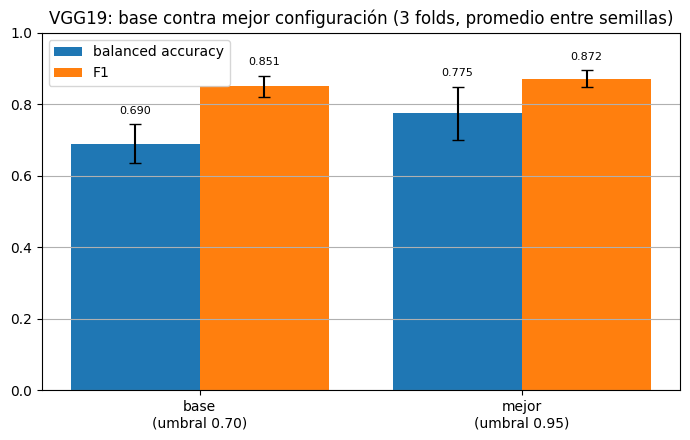

In [10]:
UMBRALES_GRILLA = np.round(np.arange(0.05, 0.96, 0.01), 2)


def juntas(folds):
    y = np.concatenate([folds[i][0] for i in folds])
    p = np.concatenate([folds[i][1] for i in folds])
    return y, p


filas, umbrales_finales = [], {}
for nombre in CONFIGS_FINALES:
    y_all = np.concatenate([juntas(FINALES[(nombre, s)])[0] for s in SEMILLAS])
    p_all = np.concatenate([juntas(FINALES[(nombre, s)])[1] for s in SEMILLAS])
    ba = [balanced_accuracy_score(y_all, (p_all >= u).astype(int)) for u in UMBRALES_GRILLA]
    umbral = float(UMBRALES_GRILLA[int(np.argmax(ba))])
    umbrales_finales[nombre] = umbral

    for s in SEMILLAS:
        folds = FINALES[(nombre, s)]
        y, p = juntas(folds)
        pred = (p >= umbral).astype(int)
        filas.append(dict(
            config=nombre, semilla=s, umbral=umbral,
            auc_folds12=np.mean([roc_auc_score(*folds[i][:2]) for i in (1, 2)]),
            balanced_accuracy=balanced_accuracy_score(y, pred),
            f1=f1_score(y, pred),
            balanced_accuracy_folds12=np.mean([balanced_accuracy_score(folds[i][0], (folds[i][1] >= umbral).astype(int))
                                               for i in (1, 2)]),
        ))

por_semilla = pd.DataFrame(filas)
print(por_semilla.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

metricas = ["auc_folds12", "balanced_accuracy", "f1", "balanced_accuracy_folds12"]
resumen = por_semilla.groupby("config", sort=False)[metricas].agg(["mean", "std"])
resumen.to_csv(DIR_TRABAJO / "comparacion_final.csv")

tabla = pd.DataFrame({"umbral": pd.Series(umbrales_finales)})
for m in metricas:
    tabla[m] = [f"{resumen.loc[n, (m, 'mean')]:.3f} ± {resumen.loc[n, (m, 'std')]:.3f}" for n in tabla.index]
print("\nPromedio ± desvío entre semillas:")
print(tabla.to_string())

# Gráfico: balanced accuracy y F1 de cada configuración (promedio ± desvío entre semillas)
x = np.arange(len(CONFIGS_FINALES))
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, (metrica, etiqueta) in enumerate([("balanced_accuracy", "balanced accuracy"), ("f1", "F1")]):
    medias = [resumen.loc[n, (metrica, "mean")] for n in CONFIGS_FINALES]
    desvios = [resumen.loc[n, (metrica, "std")] for n in CONFIGS_FINALES]
    barras = ax.bar(x + (k - 0.5) * 0.4, medias, width=0.4, yerr=desvios, capsize=4, label=etiqueta)
    ax.bar_label(barras, fmt="%.3f", fontsize=8, padding=6)
ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n(umbral {umbrales_finales[n]:.2f})" for n in CONFIGS_FINALES])
ax.set_ylim(0, 1)
ax.set_title("VGG19: base contra mejor configuración (3 folds, promedio entre semillas)")
ax.legend()
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

with open(DIR_TRABAJO / "configuracion_elegida.json", "w") as f:
    json.dump(dict(config=CONFIGS_FINALES["mejor"], umbral=umbrales_finales["mejor"],
                   config_base=CONFIG_BASE, umbral_base=umbrales_finales["base"]), f, indent=2)

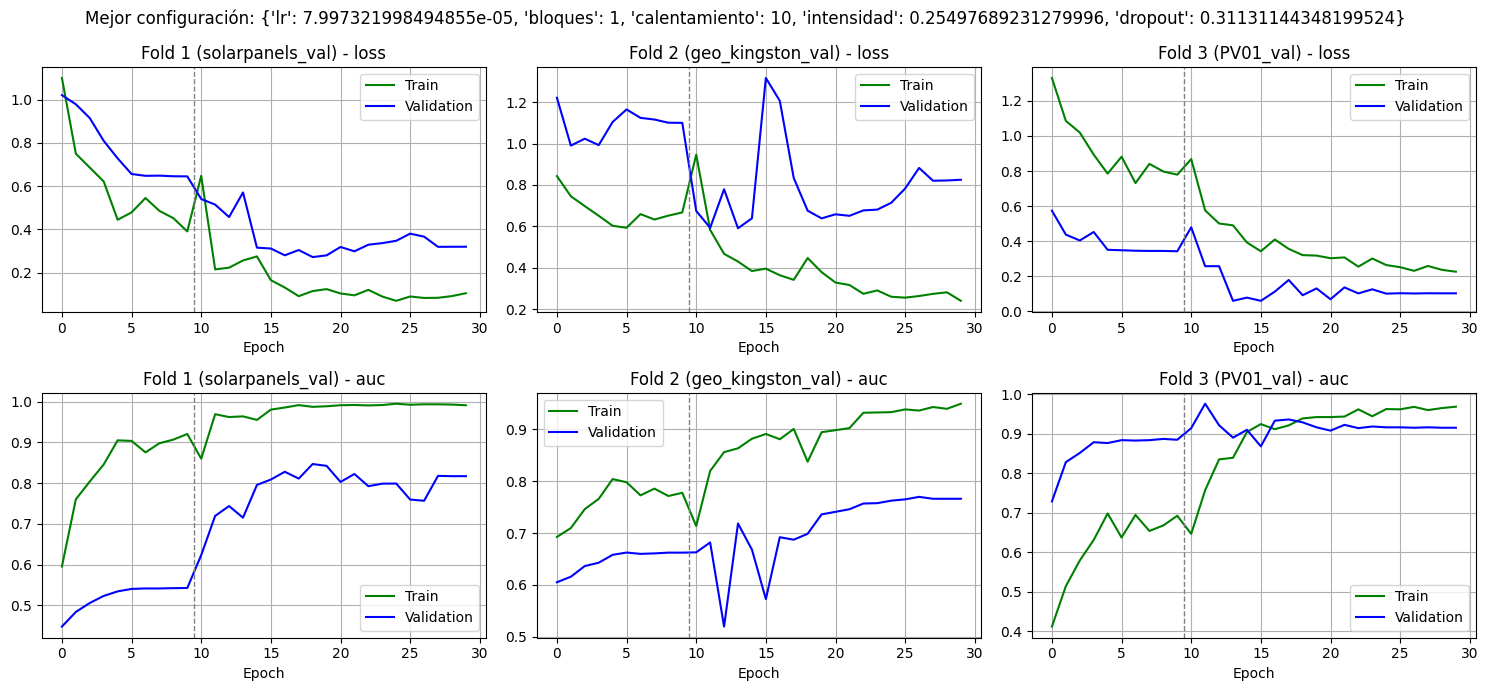

In [11]:
# Curvas de entrenamiento de la mejor configuración (primera semilla); las líneas punteadas marcan las fases
folds = FINALES[("mejor", SEMILLAS[0])]
fig, axes = plt.subplots(2, len(folds), figsize=(5 * len(folds), 7), squeeze=False)
for j, (i, (_, _, h)) in enumerate(folds.items()):
    for k, metrica in enumerate(["loss", "auc"]):
        ax = axes[k, j]
        ax.plot(h[metrica], "g", label="Train")
        ax.plot(h["val_" + metrica], "b", label="Validation")
        for corte in h["_cortes"][1:]:
            ax.axvline(corte - 0.5, color="gray", linestyle="--", linewidth=1)
        ax.set_title(f"Fold {i} ({FOLDS_CV[i][0]}) - {metrica}")
        ax.set_xlabel("Epoch")
        ax.grid(True)
        ax.legend()
fig.suptitle(f"Mejor configuración: {CONFIGS_FINALES['mejor']}")
plt.tight_layout()
plt.show()